In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
file_path = r"C:\Users\ankit\Variance-full-backup\The_SEERA_Dataset\The SEERA Dataset\Dataset Files\SEERA dataset original raw data.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="General Information",
    header=1
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (120, 20)


In [22]:
# Display first 5 rows
display(df.head())

# Display last 5 rows
display(df.tail())

# Display all column names
print("Column names:")
for col in df.columns:
    print(col)

# Display dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

,Unnamed: 0,Contract Date,Contract software delivery date,Actual software development start date,Year of project (Main),Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Contract price,Actual incurred costs,ActualEffort,% project gain (loss) (Main),Unnamed: 17,Unnamed: 18,projID
0,1,?,?,00/2015,2015,1,1,1,16,7,13,2.0,3.0,?,?,3.0,?,1,7,1
1,2,05/2016,05/2016,05/2016,2016,25,5,1,2,1,2,2.0,3.0,?,?,3.0,?,1,3,2
2,3,06/2008,03/2009,09/2008,2008,2,5,3,2,2,3,3.0,5.0,40000,40000,5.0,0,1,3,3
3,4,06/2010,01/2010,06/2009,2009,42,4,2,3,2,4,6.0,6.0,1500000,1750000,6.0,-0.166667,1,7,4
4,5,02/2016,2/1/2018,02/2016,2016,42,4,2,3,2,4,12.0,24.0,9000000000,10570000000,24.0,-0.174444,1,7,5


,Unnamed: 0,Contract Date,Contract software delivery date,Actual software development start date,Year of project (Main),Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Contract price,Actual incurred costs,ActualEffort,% project gain (loss) (Main),Unnamed: 17,Unnamed: 18,projID
115,116,03/2018,06/2018,01/2018,2018,38,1,2,16,1,13,2.0,3.0,?,?,3.0,?,4,7,120
116,117,00/1998,00/1999,00/1998,1998,4,4,1,3,3,3,6.0,18.0,100000,100000,18.0,0,1,1,121
117,118,?,?,01/2006,2006,14,2,2,16,6,13,2.0,5.0,?,?,5.0,?,1,5,125
118,119,04/2016,08/2016,?,2016,43,6,1,16,11,13,3.0,12.0,?,?,12.0,?,2,7,126
119,120,00/2016,00/2016,00/2016,2016,14,2,4,16,4,4,12.0,36.0,400000,1000000,36.0,-1.5,1,7,127


Column names:
Unnamed: 0
Contract Date
Contract software delivery date 
Actual software development start date
Year of project (Main)
Unnamed: 5
Unnamed: 6
Unnamed: 7
Unnamed: 8
Unnamed: 9
Unnamed: 10
Unnamed: 11
Unnamed: 12
Contract price 
Actual incurred costs 
ActualEffort
% project gain (loss) (Main)
Unnamed: 17
Unnamed: 18
projID
Rows: 120
Columns: 20


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 20 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Unnamed: 0                              120 non-null    int64  
 1   Contract Date                           120 non-null    object 
 2   Contract software delivery date         120 non-null    object 
 3   Actual software development start date  120 non-null    object 
 4   Year of project (Main)                  120 non-null    int64  
 5   Unnamed: 5                              120 non-null    int64  
 6   Unnamed: 6                              120 non-null    int64  
 7   Unnamed: 7                              120 non-null    int64  
 8   Unnamed: 8                              120 non-null    int64  
 9   Unnamed: 9                              120 non-null    int64  
 10  Unnamed: 10                             120 non-null    int64 

In [24]:
# Count missing values in each column
missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": missing_values.values,
    "Missing_Percentage": (
        missing_values.values / len(df) * 100
    ).round(2)
})

display(
    missing_table[
        missing_table["Missing_Count"] > 0
    ].sort_values("Missing_Count", ascending=False)
)

,Column,Missing_Count,Missing_Percentage
16,% project gain (loss) (Main),17,14.17


In [25]:
for col in df.select_dtypes(include="object").columns:
    print(
        col,
        df[col].astype(str).str.strip().isin(
            ["?", "-", "NA", "N/A", "nan", ""]
        ).sum()
    )

Contract Date 13
Contract software delivery date  14
Actual software development start date 8
Contract price  39
Actual incurred costs  39
% project gain (loss) (Main) 56


In [26]:
unnamed_columns = [
    col for col in df.columns
    if str(col).strip().lower().startswith("unnamed")
]

print("Unnamed columns:", unnamed_columns)

display(df[unnamed_columns].head() if unnamed_columns else df.head())

Unnamed columns: ['Unnamed: 0', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 17', 'Unnamed: 18']


,Unnamed: 0,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 17,Unnamed: 18
0,1,1,1,1,16,7,13,2.0,3.0,1,7
1,2,25,5,1,2,1,2,2.0,3.0,1,3
2,3,2,5,3,2,2,3,3.0,5.0,1,3
3,4,42,4,2,3,2,4,6.0,6.0,1,7
4,5,42,4,2,3,2,4,12.0,24.0,1,7


In [27]:
columns_to_remove = [
    col for col in unnamed_columns
    if df[col].isna().all()
]

df = df.drop(columns=columns_to_remove)

print("Updated shape:", df.shape)

Updated shape: (120, 20)


In [28]:
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df.columns.tolist())

['unnamed_0', 'contract_date', 'contract_software_delivery_date', 'actual_software_development_start_date', 'year_of_project_main', 'unnamed_5', 'unnamed_6', 'unnamed_7', 'unnamed_8', 'unnamed_9', 'unnamed_10', 'unnamed_11', 'unnamed_12', 'contract_price', 'actual_incurred_costs', 'actualeffort', 'project_gain_loss_main', 'unnamed_17', 'unnamed_18', 'projid']


In [29]:

# Check missing-value indicators in each column

missing_indicators = ["?", "-", "NA", "N/A", "nan", ""]

for col in df.select_dtypes(include="object").columns:
    count = df[col].astype(str).str.strip().isin(missing_indicators).sum()
    print(f"{col}: {count}")


contract_date: 13
contract_software_delivery_date: 14
actual_software_development_start_date: 8
contract_price: 39
actual_incurred_costs: 39
project_gain_loss_main: 56


In [31]:



missing_indicators = ["?", "-", "NA", "N/A", "nan", ""]

df = df.replace(missing_indicators, np.nan)

print("Missing values converted successfully!")

print("\nMissing values in each column:")
print(df.isnull().sum()[df.isnull().sum() > 0])



Missing values converted successfully!

Missing values in each column:
contract_date                             13
contract_software_delivery_date           14
actual_software_development_start_date     8
contract_price                            39
actual_incurred_costs                     39
project_gain_loss_main                    56
dtype: int64


In [32]:

missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values("Missing_Percentage", ascending=False)

display(missing_summary)


,Missing_Count,Missing_Percentage
project_gain_loss_main,56,46.67
contract_price,39,32.50
actual_incurred_costs,39,32.50
contract_software_delivery_date,14,11.67
contract_date,13,10.83
actual_software_development_start_date,8,6.67


In [33]:

print("Column Data Types:\n")
print(df.dtypes)


Column Data Types:

unnamed_0                                   int64
contract_date                              object
contract_software_delivery_date            object
actual_software_development_start_date     object
year_of_project_main                        int64
unnamed_5                                   int64
unnamed_6                                   int64
unnamed_7                                   int64
unnamed_8                                   int64
unnamed_9                                   int64
unnamed_10                                  int64
unnamed_11                                float64
unnamed_12                                float64
contract_price                             object
actual_incurred_costs                      object
actualeffort                              float64
project_gain_loss_main                    float64
unnamed_17                                  int64
unnamed_18                                  int64
projid                        

In [34]:

print("Contract Price - Sample Values:")
print(df["contract_price"].dropna().unique()[:15])

print("\nActual Incurred Costs - Sample Values:")
print(df["actual_incurred_costs"].dropna().unique()[:15])


Contract Price - Sample Values:
[40000 1500000 9000000000 254000000 154000000 200000000 480000 60000 15000
 47500 39000 20000 80000 8000 198672]

Actual Incurred Costs - Sample Values:
[40000 1750000 10570000000 254000000 154000000 200000000 480000 75000
 15000 'Not exist' 80000 3750000 16600000 600000 212550]


In [35]:

df["actual_incurred_costs"] = df["actual_incurred_costs"].replace(
    "Not exist", np.nan
)

print(
    "Count of 'Not exist' remaining:",
    df["actual_incurred_costs"].eq("Not exist").sum()
)

print(
    "Missing values in actual_incurred_costs:",
    df["actual_incurred_costs"].isnull().sum()
)


Count of 'Not exist' remaining: 0
Missing values in actual_incurred_costs: 55


C:\Users\ankit\AppData\Local\Temp\ipykernel_19656\1603455089.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["actual_incurred_costs"] = df["actual_incurred_costs"].replace(


In [36]:

print("Remaining 'Not exist':",
      df["actual_incurred_costs"].eq("Not exist").sum())

print("Missing values:",
      df["actual_incurred_costs"].isnull().sum())

print("Data type:",
      df["actual_incurred_costs"].dtype)


Remaining 'Not exist': 0
Missing values: 55
Data type: float64


In [37]:

print("Contract price data type:", df["contract_price"].dtype)

print("\nNon-numeric values in contract_price:")

numeric_values = pd.to_numeric(
    df["contract_price"], errors="coerce"
)

invalid_values = df[
    df["contract_price"].notna() & numeric_values.isna()
]["contract_price"]

print(invalid_values.unique())
print("Invalid value count:", len(invalid_values))


Contract price data type: object

Non-numeric values in contract_price:
['Not exist']
Invalid value count: 1


In [38]:

df["contract_price"] = df["contract_price"].replace(
    "Not exist", np.nan
)

print("Remaining 'Not exist':",
      df["contract_price"].eq("Not exist").sum())

print("Missing values:",
      df["contract_price"].isnull().sum())

print("Data type:",
      df["contract_price"].dtype)


Remaining 'Not exist': 0
Missing values: 40
Data type: float64


C:\Users\ankit\AppData\Local\Temp\ipykernel_19656\1579132944.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["contract_price"] = df["contract_price"].replace(


In [39]:

numeric_columns = ["contract_price", "actual_incurred_costs"]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[numeric_columns].dtypes)

print("\nMissing values:")
print(df[numeric_columns].isnull().sum())


contract_price           float64
actual_incurred_costs    float64
dtype: object

Missing values:
contract_price           40
actual_incurred_costs    55
dtype: int64


In [40]:

date_columns = [
    "contract_date",
    "contract_software_delivery_date",
    "actual_software_development_start_date"
]

for col in date_columns:
    print(f"\n{col}:")
    print(df[col].dropna().unique()[:10])



contract_date:
['05/2016' '06/2008' '06/2010' '02/2016' '12/2012' '00/2016' '07/2018'
 '00/2018' '08/2015' '00/2001']

contract_software_delivery_date:
['05/2016' '03/2009' '01/2010' '2/1/2018' '05/2013' '00/2016' '12/2018'
 '00/2018' '10/2019' '00/2005']

actual_software_development_start_date:
['00/2015' '05/2016' '09/2008' '06/2009' '02/2016' '12/2012' '00/2016'
 '07/2018' '00/2018' '10/2015']


In [41]:

date_columns = [
    "contract_date",
    "contract_software_delivery_date",
    "actual_software_development_start_date"
]

for col in date_columns:
    count = df[col].astype(str).str.strip().str.startswith("00/").sum()
    print(f"{col}: {count} values start with '00/'")


contract_date: 33 values start with '00/'
contract_software_delivery_date: 35 values start with '00/'
actual_software_development_start_date: 42 values start with '00/'


In [42]:

for col in date_columns:
    print(f"\n{col}:")
    
    invalid_dates = df.loc[
        df[col].astype(str).str.strip().str.startswith("00/"),
        col
    ]
    
    print(invalid_dates.head(10).to_list())



contract_date:
['00/2016', '00/2018', '00/2001', '00/2000', '00/2008', '00/2011', '00/2004', '00/2011', '00/2018', '00/2014']

contract_software_delivery_date:
['00/2016', '00/2018', '00/2005', '00/2000', '00/2009', '00/2008', '00/2011', '00/2005', '00/2012', '00/2018']

actual_software_development_start_date:
['00/2015', '00/2016', '00/2018', '00/2001', '00/2000', '00/2009', '00/2008', '00/2011', '00/2004', '00/2011']


In [43]:

for col in date_columns:
    mask = df[col].astype(str).str.strip().str.startswith("00/")
    df.loc[mask, col] = np.nan

print("Remaining invalid dates:")

for col in date_columns:
    count = df[col].astype(str).str.strip().str.startswith("00/").sum()
    print(f"{col}: {count}")

print("\nMissing values in date columns:")
print(df[date_columns].isnull().sum())



Remaining invalid dates:
contract_date: 0
contract_software_delivery_date: 0
actual_software_development_start_date: 0

Missing values in date columns:
contract_date                             46
contract_software_delivery_date           49
actual_software_development_start_date    50
dtype: int64


In [44]:

for col in date_columns:
    print(f"\n{col}:")
    print(df[col].dropna().unique()[:15])



contract_date:
['05/2016' '06/2008' '06/2010' '02/2016' '12/2012' '07/2018' '08/2015'
 '03/2000' '11/2016' '05/2009' '02/2010' '01/2016' '11/2014' '03/2012'
 '02/2014']

contract_software_delivery_date:
['05/2016' '03/2009' '01/2010' '2/1/2018' '05/2013' '12/2018' '10/2019'
 '09/2000' '02/2017' '8/2009' '06/2010' '06/2014' '3/2019' '3/2017'
 '01/2019']

actual_software_development_start_date:
['05/2016' '09/2008' '06/2009' '02/2016' '12/2012' '07/2018' '10/2015'
 '03/2000' '04/2017' '03/2010' '03/2016' '02/2015' '06/2012' '03/2014'
 '01/2019']


In [45]:

for col in date_columns:
    full_date_mask = (
        df[col].astype(str).str.strip()
        .str.match(r"^\d{1,2}/\d{1,2}/\d{4}$")
    )

    print(f"{col}: {full_date_mask.sum()} full-date values")

    print("Examples:", df.loc[full_date_mask, col].head(5).to_list())


contract_date: 0 full-date values
Examples: []
contract_software_delivery_date: 1 full-date values
Examples: ['2/1/2018']
actual_software_development_start_date: 0 full-date values
Examples: []


In [46]:

for col in date_columns:
    mask = df[col].astype(str).str.strip().str.match(
        r"^\d{1,2}/\d{4}$"
    )

    df.loc[mask, col] = pd.to_datetime(
        df.loc[mask, col].astype(str).str.strip(),
        format="%m/%Y",
        errors="coerce"
    ).dt.strftime("%Y-%m-01")

print(df[date_columns].head(10))


  contract_date contract_software_delivery_date  \
0           NaN                             NaN   
1    2016-05-01                      2016-05-01   
2    2008-06-01                      2009-03-01   
3    2010-06-01                      2010-01-01   
4    2016-02-01                        2/1/2018   
5    2012-12-01                      2013-05-01   
6           NaN                             NaN   
7    2018-07-01                      2018-12-01   
8           NaN                             NaN   
9    2015-08-01                      2019-10-01   

  actual_software_development_start_date  
0                                    NaN  
1                             2016-05-01  
2                             2008-09-01  
3                             2009-06-01  
4                             2016-02-01  
5                             2012-12-01  
6                                    NaN  
7                             2018-07-01  
8                                    NaN  
9       

In [47]:

for col in date_columns:
    print(f"\n{col}")
    print("Data type:", df[col].dtype)
    print("Remaining values:")
    print(df[col].dropna().unique()[:10])



contract_date
Data type: object
Remaining values:
['2016-05-01' '2008-06-01' '2010-06-01' '2016-02-01' '2012-12-01'
 '2018-07-01' '2015-08-01' '2000-03-01' '2016-11-01' '2009-05-01']

contract_software_delivery_date
Data type: object
Remaining values:
['2016-05-01' '2009-03-01' '2010-01-01' '2/1/2018' '2013-05-01'
 '2018-12-01' '2019-10-01' '2000-09-01' '2017-02-01' '2009-08-01']

actual_software_development_start_date
Data type: object
Remaining values:
['2016-05-01' '2008-09-01' '2009-06-01' '2016-02-01' '2012-12-01'
 '2018-07-01' '2015-10-01' '2000-03-01' '2017-04-01' '2010-03-01']


In [48]:

for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        format="%Y-%m-%d",
        errors="coerce"
    )

print(df[date_columns].dtypes)

print("\nMissing values after date conversion:")
print(df[date_columns].isnull().sum())


contract_date                             datetime64[ns]
contract_software_delivery_date           datetime64[ns]
actual_software_development_start_date    datetime64[ns]
dtype: object

Missing values after date conversion:
contract_date                             46
contract_software_delivery_date           50
actual_software_development_start_date    50
dtype: int64


In [49]:

missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values("Missing_Count", ascending=False)

display(missing_summary)


,Missing_Count,Missing_Percentage
project_gain_loss_main,56,46.67
actual_incurred_costs,55,45.83
actual_software_development_start_date,50,41.67
contract_software_delivery_date,50,41.67
contract_date,46,38.33
contract_price,40,33.33


In [51]:
# Check statistical summary of numeric columns
display(df[[
    "contract_price",
    "actual_incurred_costs",
    "project_gain_loss_main"
]].describe())

,contract_price,actual_incurred_costs,project_gain_loss_main
count,8.000000e+01,6.500000e+01,64.000000
mean,1.332184e+08,1.876351e+08,-0.041503
std,1.007326e+09,1.311116e+09,0.371092
min,2.000000e+03,2.000000e+03,-1.500000
25%,4.375000e+04,3.500000e+04,0.000000
50%,2.375000e+05,2.000000e+05,0.000000
75%,1.891250e+06,2.406000e+06,0.041471
max,9.000000e+09,1.057000e+10,0.629630


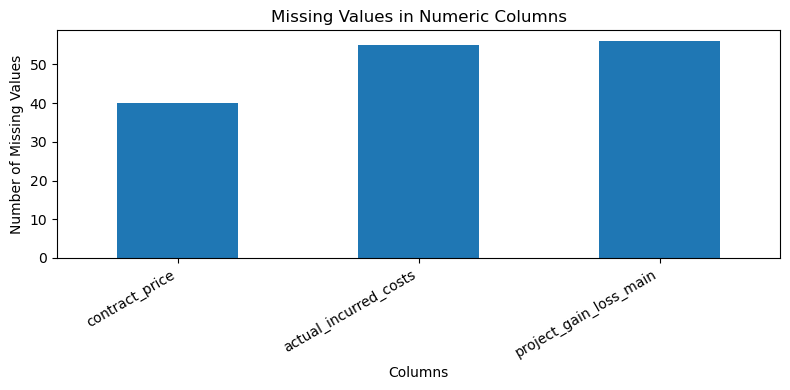

In [52]:
import matplotlib.pyplot as plt

numeric_columns = [
    "contract_price",
    "actual_incurred_costs",
    "project_gain_loss_main"
]

df[numeric_columns].isnull().sum().plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Missing Values in Numeric Columns")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [53]:
date_columns = [
    "contract_date",
    "contract_software_delivery_date",
    "actual_software_development_start_date"
]

for col in date_columns:
    print(f"{col}: {df[col].isnull().sum()} missing values")

contract_date: 46 missing values
contract_software_delivery_date: 50 missing values
actual_software_development_start_date: 50 missing values


In [54]:
# Display rows where any date column is missing
display(
    df.loc[
        df[date_columns].isnull().any(axis=1),
        ["projid"] + date_columns
    ].head(10)
)

,projid,contract_date,contract_software_delivery_date,actual_software_development_start_date
0,1,NaT,NaT,NaT
4,5,2016-02-01,NaT,2016-02-01
6,7,NaT,NaT,NaT
8,9,NaT,NaT,NaT
10,11,NaT,NaT,NaT
16,17,2014-11-01,NaT,2015-02-01
17,18,2012-03-01,NaT,2012-06-01
21,22,NaT,NaT,NaT
22,23,NaT,NaT,NaT
23,24,NaT,NaT,NaT


In [55]:
# Count rows where all three dates are missing
all_dates_missing = df[date_columns].isnull().all(axis=1).sum()

# Count rows where at least one date is missing
any_date_missing = df[date_columns].isnull().any(axis=1).sum()

print("Rows with all three dates missing:", all_dates_missing)
print("Rows with at least one date missing:", any_date_missing)

Rows with all three dates missing: 41
Rows with at least one date missing: 59


In [56]:
# Check available gain/loss values
print("Available values:")
print(df["project_gain_loss_main"].dropna().sort_values().to_list())

print("\nDescriptive statistics:")
display(df["project_gain_loss_main"].describe())

Available values:
[-1.5, -1.2222222222222223, -1.0215633423180592, -1.0, -1.0, -0.25, -0.2222222222222222, -0.21212121212121213, -0.17444444444444446, -0.16666666666666666, -0.14285714285714285, -0.13333333333333333, -0.04352941176470588, -0.013529411764705882, -0.013529411764705882, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.026470588235294117, 0.036470588235294116, 0.036470588235294116, 0.05647058823529412, 0.05647058823529412, 0.07647058823529412, 0.08647058823529412, 0.09375, 0.11647058823529412, 0.16647058823529412, 0.2, 0.25, 0.3333333333333333, 0.4115384615384615, 0.43, 0.4533333333333333, 0.5, 0.5, 0.6296296296296297]

Descriptive statistics:


count    64.000000
mean     -0.041503
std       0.371092
min      -1.500000
25%       0.000000
50%       0.000000
75%       0.041471
max       0.629630
Name: project_gain_loss_main, dtype: float64

In [57]:
display(
    df[
        [
            "contract_price",
            "actual_incurred_costs",
            "project_gain_loss_main"
        ]
    ].corr().round(3)
)

,contract_price,actual_incurred_costs,project_gain_loss_main
contract_price,1.000,1.000,-0.043
actual_incurred_costs,1.000,1.000,-0.044
project_gain_loss_main,-0.043,-0.044,1.000


In [58]:
display(
    df[
        [
            "projid",
            "contract_price",
            "actual_incurred_costs",
            "project_gain_loss_main"
        ]
    ].dropna(
        subset=["contract_price", "actual_incurred_costs"]
    ).head(10)
)

,projid,contract_price,actual_incurred_costs,project_gain_loss_main
2,3,4.000000e+04,4.000000e+04,0.000000
3,4,1.500000e+06,1.750000e+06,-0.166667
4,5,9.000000e+09,1.057000e+10,-0.174444
5,6,2.540000e+08,2.540000e+08,0.000000
6,7,1.540000e+08,1.540000e+08,0.000000
8,9,2.000000e+08,2.000000e+08,0.000000
9,10,4.800000e+05,4.800000e+05,0.000000
10,11,6.000000e+04,7.500000e+04,-0.250000
11,12,1.500000e+04,1.500000e+04,0.000000
19,20,2.160000e+05,8.000000e+04,0.629630


In [59]:
# Check missing values in the three related columns
cols = [
    "contract_price",
    "actual_incurred_costs",
    "project_gain_loss_main"
]

display(
    df.loc[
        df[cols].isnull().any(axis=1),
        ["projid"] + cols
    ].head(15)
)

,projid,contract_price,actual_incurred_costs,project_gain_loss_main
0,1,NaN,NaN,NaN
1,2,NaN,NaN,NaN
7,8,NaN,NaN,NaN
12,13,47500.0,NaN,NaN
13,14,39000.0,NaN,NaN
14,15,20000.0,NaN,NaN
15,16,80000.0,NaN,NaN
16,17,40000.0,NaN,NaN
17,18,8000.0,NaN,NaN
18,19,198672.0,NaN,NaN


In [60]:
# 1. Make a copy of the original dataframe
df_clean = df.copy()

# 2. Fill numeric missing values with median
numeric_columns = [
    "contract_price",
    "actual_incurred_costs",
    "project_gain_loss_main"
]

for col in numeric_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# 3. Keep missing dates as NaT (do not guess dates)

# 4. Verify missing values
print("Missing values after handling:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nTotal missing cells:", df_clean.isnull().sum().sum())

Missing values after handling:
contract_date                             46
contract_software_delivery_date           50
actual_software_development_start_date    50
dtype: int64

Total missing cells: 146


In [61]:
# Final verification
print("Dataset shape:", df_clean.shape)
print("Total missing values:", df_clean.isnull().sum().sum())



Dataset shape: (120, 20)
Total missing values: 146
